# Part 3 Washing-machine disaggregation

This notebook estimates washing-machine power from the household aggregate signal. It trains on Houses 1, 2, and 3 and evaluates on unseen House 5, so nearby windows from the same household are not randomly mixed between training and testing.

## Method and validation design

The target is one-minute washing-machine power. The model uses current and lagged aggregate power, five-minute rolling aggregate statistics, hour of day, and day of week. Rows with missing values, long-gap flags, or insufficient lag history are excluded. Rows marked `Issues == 1` are treated as unreliable by the shared resampling function.

Houses 1–3 are used for training and House 5 is held out for testing. This household-level split avoids leakage from overlapping windows and tests generalisation to a different home. The always-off baseline predicts zero watts for every minute. A minute is considered active when washing-machine power exceeds 20 W.

In [1]:
# Methods for loading, cleaning, and analyzing the REFIT dataset.

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = Path.cwd().resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from eda import load_house, resample_house
from model import (
    build_features,
    evaluate_baseline,
    evaluate_predictions,
    fit_model,
    predict_non_negative,
)

CLEAN_DIR = PROJECT_ROOT / "data" / "cleaned" / "CLEAN_REFIT_081116"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WASHER_CHANNELS = {
    1: "Appliance5",
    2: "Appliance2",
    3: "Appliance6",
    5: "Appliance3",
}
TRAIN_HOUSES = (1, 2, 3)
TEST_HOUSE = 5
CONFIG = {
    "max_gap_minutes": 3,
    "active_power_watts": 20.0,
    "random_state": 42,
}

print(f"Training houses: {TRAIN_HOUSES}")
print(f"Test house: {TEST_HOUSE}")
print(f"Cleaned data: {CLEAN_DIR}")

Training houses: (1, 2, 3)
Test house: 5
Cleaned data: D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\data\cleaned\CLEAN_REFIT_081116


In [2]:
# Load and resample the data for each house, then build features and targets for disaggregation.

house_data = {}
feature_data = {}
summary_rows = []

for house_number, washer_column in WASHER_CHANNELS.items():
    raw = load_house(CLEAN_DIR, house_number, washer_column)
    minute_data, report = resample_house(
        raw,
        washer_column,
        max_gap_minutes=CONFIG["max_gap_minutes"],
    )
    features, target = build_features(minute_data, washer_column)
    house_data[house_number] = {
        "data": minute_data,
        "washer_column": washer_column,
        "report": report,
    }
    feature_data[house_number] = {"features": features, "target": target}
    summary_rows.append(
        {
            "house": house_number,
            "washer_channel": washer_column,
            **report,
            "feature_rows": len(features),
        }
    )

x_train = pd.concat(
    [feature_data[house]["features"] for house in TRAIN_HOUSES],
)
y_train = pd.concat(
    [feature_data[house]["target"] for house in TRAIN_HOUSES],
)
x_test = feature_data[TEST_HOUSE]["features"]
y_test = feature_data[TEST_HOUSE]["target"]
pd.DataFrame(summary_rows).to_csv(
    OUTPUT_DIR / "disaggregation_data_summary.csv",
    index=False,
)

print(f"Training rows: {len(x_train):,}")
print(f"Testing rows: {len(x_test):,}")
display(x_train.head())

Training rows: 2,200,400
Testing rows: 790,498


,aggregate_lag_0,aggregate_lag_1,aggregate_lag_2,aggregate_lag_3,aggregate_lag_5,aggregate_lag_10,aggregate_rolling_mean_5,aggregate_rolling_max_5,hour,day_of_week
Time,,,,,,,,,,
2013-10-09 13:16:00,1350.2,1370.2,1346.7,1429.0,854.2,529.666667,1359.68,1429.0,13,2
2013-10-09 13:17:00,1361.7,1350.2,1370.2,1346.7,1302.3,543.875000,1371.56,1429.0,13,2
2013-10-09 13:18:00,1404.2,1361.7,1350.2,1370.2,1429.0,578.000000,1366.60,1404.2,13,2
2013-10-09 13:19:00,1775.8,1404.2,1361.7,1350.2,1346.7,638.300000,1452.42,1775.8,13,2
2013-10-09 13:20:00,1855.8,1775.8,1404.2,1361.7,1370.2,800.200000,1549.54,1855.8,13,2


In [3]:
# Fit a model to the training data and evaluate it on the test data.

model = fit_model(
    x_train,
    y_train,
    random_state=CONFIG["random_state"],
)
predicted = predict_non_negative(model, x_test)

results = pd.DataFrame(
    [
        {
            "method": "Always off",
            **evaluate_baseline(
                y_test,
                CONFIG["active_power_watts"],
            ),
        },
        {
            "method": "HistGradientBoosting",
            **evaluate_predictions(
                y_test,
                predicted,
                CONFIG["active_power_watts"],
            ),
        },
    ]
)
display(results.round(3))
results.to_csv(OUTPUT_DIR / "disaggregation_model_results.csv", index=False)

,method,mae_watts,rmse_watts,actual_energy_wh,predicted_energy_wh,energy_error_percent,active_precision,active_recall,active_f1
0,Always off,22.998,167.303,302994.394,0.000,100.000,0.000,0.000,0.000
1,HistGradientBoosting,33.744,160.216,302994.394,261945.713,13.548,0.215,0.435,0.288


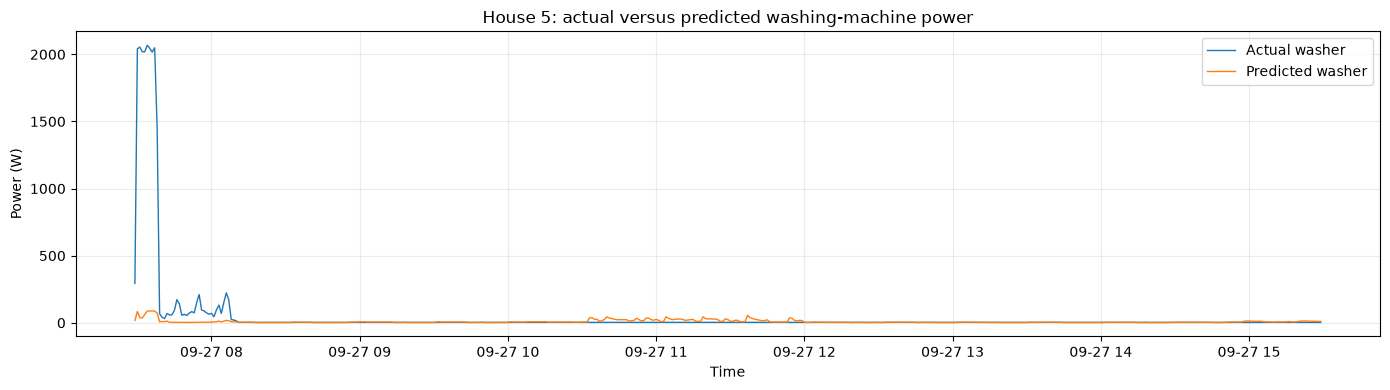

,method,mae_watts,rmse_watts,actual_energy_wh,predicted_energy_wh,energy_error_percent,active_precision,active_recall,active_f1
0,Always off,22.998,167.303,302994.394,0.000,100.000,0.000,0.000,0.000
1,HistGradientBoosting,33.744,160.216,302994.394,261945.713,13.548,0.215,0.435,0.288


In [4]:
# actual versus predicted plot for the test house

active_test_times = y_test[y_test > CONFIG["active_power_watts"]].index
if active_test_times.empty:
    plot_start = y_test.index.min()
else:
    plot_start = active_test_times[0]
plot_window = y_test.loc[plot_start : plot_start + pd.Timedelta(hours=8)].index

figure, axis = plt.subplots(figsize=(14, 4))
axis.plot(plot_window, y_test.loc[plot_window], label="Actual washer", linewidth=1)
axis.plot(plot_window, predicted.loc[plot_window], label="Predicted washer", linewidth=1)
axis.set_title(f"House {TEST_HOUSE}: actual versus predicted washing-machine power")
axis.set_xlabel("Time")
axis.set_ylabel("Power (W)")
axis.legend()
axis.grid(alpha=0.25)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "disaggregation_actual_vs_predicted.png", dpi=150)
plt.show()
display(results.round(3))

## Results and interpretation

MAE and RMSE measure minute-level power error. Energy error measures whether the total estimated washer consumption is close to the observed total. Active precision, recall, and F1 measure event detection and are important because the washer is off for most minutes.

In the current run, the model achieves 33.74 W MAE, 160.22 W RMSE, 13.55% energy error, and 0.288 active-state F1 on House 5. The always-off baseline has 22.998 W MAE but 100% energy error and zero active-state F1. The model should therefore not be judged by MAE alone: an always-off predictor can achieve a deceptively competitive MAE under severe class imbalance. The model may struggle when another appliance has a similar aggregate signature, when a washer phase is short or low power, or when the held-out household behaves differently from the training households. Long missing intervals are excluded rather than filled artificially.